Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.2053 - loss: 2.2805 - val_accuracy: 0.4219 - val_loss: 2.2431
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3858 - loss: 2.2112 - val_accuracy: 0.5202 - val_loss: 2.1716
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5229 - loss: 2.1294 - val_accuracy: 0.6003 - val_loss: 2.0719
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5933 - loss: 2.0118 - val_accuracy: 0.6631 - val_loss: 1.9288
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6455 - loss: 1.8476 - val_accuracy: 0.6635 - val_loss: 1.7381
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6816 - loss: 1.6445 - val_accuracy: 0.7032 - val_loss: 1.5199
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7140 - loss: 1.4296 - val_accuracy: 0.7367 - val_loss: 1.3081
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7421 - loss: 1.2342 - val_accuracy: 0.

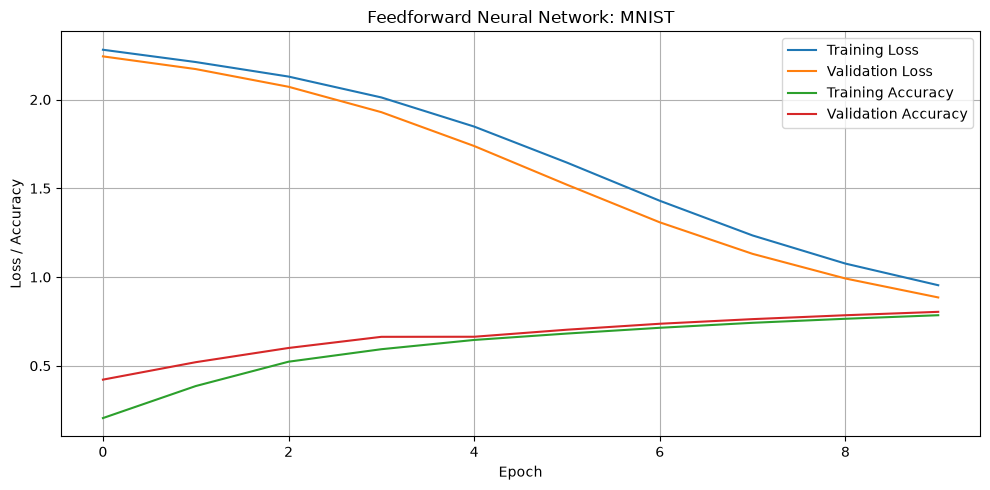

In [4]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report

(trainX, trainY), (testX, testY) = mnist.load_data()

trainX = trainX.reshape(-1, 784).astype("float32") / 255.0
testX = testX.reshape(-1, 784).astype("float32") / 255.0
trainY = to_categorical(trainY, 10)
testY = to_categorical(testY, 10)

model = Sequential([
    Input(shape=(784,)),
    Dense(256, activation="sigmoid"),
    Dense(128, activation="sigmoid"),
    Dense(10, activation="softmax")
])

model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    trainX, trainY,
    validation_data=(testX, testY),
    epochs=10,
    batch_size=128,
    verbose=1
)

loss, accuracy = model.evaluate(testX, testY, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

predictions = model.predict(testX, batch_size=128, verbose=0)
print(classification_report(
    np.argmax(testY, axis=1),
    np.argmax(predictions, axis=1),
    target_names=[str(i) for i in range(10)]
))

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Feedforward Neural Network: MNIST")
plt.xlabel("Epoch")
plt.ylabel("Loss / Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
